# BANKING77 experiments: preprocessing, TF-IDF / MiniLM, Logistic Regression / linear SVM

This notebook is the controller for the development protocol in `PLAN.md`. All logic lives in `banking_nlp/`;
cells only call functions and display saved artifacts.

* **Fitting partition (8,003 rows)**: TF-IDF vocabulary/IDF and classifiers are fitted here only.
* **Model validation (1,000 rows)**: preprocessing ablation, `C`, n-grams, model choice.
* **Routing validation (1,000 rows)**: untouched here; reserved for the review threshold.
* **Official test (3,080 rows)**: locked. `load_test_*` refuse to run until `selection.json` is frozen
  and the final cell is switched on explicitly.

Edit the switches in the next cell. With the defaults, saved results are loaded instead of recomputed.

In [1]:
from pathlib import Path
ROOT = Path('..').resolve() if Path.cwd().name == 'notebooks' else Path('.').resolve()

RUN_LEXICAL = False      # True: recompute the 128-fit lexical grid (~15 min on 2 CPUs)
RUN_EMBEDDINGS = False   # True: encode with MiniLM (needs sentence-transformers + Hugging Face access)
RUN_SELECT = False       # True: measure latency for C1-C4 on this machine and freeze selection.json
RUN_FINAL_TEST = False   # True only after selection.json is frozen; runs once

In [2]:
import json, sys
import pandas as pd
sys.path.insert(0, str(ROOT))
from banking_nlp import experiments as E, data as D
from banking_nlp.artifacts import load_json
from banking_nlp.preprocessing import LEXICAL_VARIANTS, preprocess_lexical, protected_words
pd.set_option('display.max_colwidth', 120)
P = E.Paths(ROOT)
splits = E.prepare(ROOT)            # loads the frozen assignment if it exists
labels = D.load_label_names(P.raw)
print(json.dumps(load_json(P.data / 'split_summary.json'), indent=1))

{
 "counts": {
  "fit": 8003,
  "model_val": 1000,
  "routing_val": 1000
 },
 "fractions": {
  "fit": 0.8001,
  "model_val": 0.1,
  "routing_val": 0.1
 },
 "requested_fractions": {
  "fit": 0.8,
  "model_val": 0.1,
  "routing_val": 0.1
 },
 "per_label_min": {
  "fit": 28,
  "model_val": 3,
  "routing_val": 4
 },
 "per_label_max": {
  "fit": 151,
  "model_val": 18,
  "routing_val": 19
 },
 "duplicate_groups": 9872,
 "multi_row_groups": 115,
 "largest_group_size": 5,
 "pairs_cosine_0.85_or_more_across_partitions": 57,
 "note": "pairs between 0.85 and 0.90 are allowed to cross partitions; many are minimal pairs with different intents",
 "splits_csv_sha256": "2d1384376ca40af8807e73a62ba8f6fe8a7ba318a7dfaa902c963ba75206559e",
 "config_hash": "b7938aa546ed"
}


## 1. Training audit (official training only)

In [3]:
audit = load_json(P.data / 'train_audit.json')
print('rows', audit['rows'], '| labels', audit['labels_present'], '| blank', audit['empty_or_blank_texts'])
print('whitespace irregularities', audit['texts_with_whitespace_irregularities'], '| multiline', audit['multiline_texts'])
print('non-ASCII', audit['non_ascii_characters'])
print('words per request', {k: round(v, 1) for k, v in audit['length_words'].items()})
print('label frequency', audit['label_frequency'])
for k in ('exact_duplicates', 'loose_duplicates'):
    d = audit[k]; print(k, '| groups', d['groups_with_duplicates'], '| rows', d['rows_in_duplicate_groups'], '| conflicting', d['conflicting_label_groups'])
print('conflict:', audit['loose_duplicates']['conflict_examples'])
nd = audit['near_duplicate_candidates']; print('near-duplicate pairs (merged):', nd['pairs'], '| same label:', nd['pairs_with_same_label'])
pd.DataFrame(nd['examples'][:5])

rows 10003 | labels 77 | blank 0
whitespace irregularities 464 | multiline 10
non-ASCII {'U+00A3 POUND SIGN': 30, 'U+20AC EURO SIGN': 21, 'U+00A0 NO-BREAK SPACE': 2, 'U+2026 HORIZONTAL ELLIPSIS': 1}
words per request {'count': 10003.0, 'mean': 11.9, 'std': 7.9, 'min': 2.0, '5%': 5.0, '50%': 10.0, '95%': 29.0, 'max': 79.0}
label frequency {'min': 35, 'max': 187, 'median': 127.0, 'least_frequent': {'lost_or_stolen_card': 82, 'card_swallowed': 61, 'card_acceptance': 59, 'virtual_card_not_working': 41, 'contactless_not_working': 35}, 'most_frequent': {'card_payment_fee_charged': 187, 'direct_debit_payment_not_recognised': 182, 'balance_not_updated_after_cheque_or_cash_deposit': 181, 'wrong_amount_of_cash_received': 180, 'cash_withdrawal_charge': 177}}
exact_duplicates | groups 4 | rows 8 | conflicting 0
loose_duplicates | groups 31 | rows 62 | conflicting 1
conflict: [{'text': 'Has my top up gone through?', 'labels': ['pending_top_up', 'top_up_reverted'], 'row_ids': ['train-02002', 'train-

,a,b,cosine,labels
0,My card payment didn't go through.,Card payment didn't go through.,0.978,"[declined_card_payment, declined_card_payment]"
1,"Looks like my card payment was duplicated after all. I went to pay at the store earlier, got declined once, second t...","Looks like my card payment was duplicated after all. I went to pay at the store earlier, got declined once,second ti...",0.976,"[transaction_charged_twice, transaction_charged_twice]"
2,"Would you please check my Card. As Withdrawal was working fine so far, but this morning suddenly got declined. Can y...","Please check my Card. As Withdrawal was working fine so far, but this morning suddenly got declined. Can you please ...",0.975,"[declined_cash_withdrawal, declined_cash_withdrawal]"
3,"I bought something online a couple days ago, sent the money immediately online but the seller says it's still not th...","How long do EU transfers actually take? I bought something online a couple days ago, sent the money immediately onli...",0.973,"[pending_transfer, pending_transfer]"
4,Money that I have transferred hasn't arrived yet,The money that I have transferred hasn't arrived yet.,0.973,"[balance_not_updated_after_bank_transfer, balance_not_updated_after_bank_transfer]"


## 2. Preprocessing

Why the defaults are not good enough here: scikit-learn's default tokenizer turns `can't` into `can` and drops
`£5`, and its generic stop-word list contains `not`, `why`, `top`, `up`, `back` and `get`.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
prot = protected_words(labels)
s = "Why can't I top-up?  I was charged £5 twice and didn’t get my money back."
print('L0 sklearn analyzer :', TfidfVectorizer().build_analyzer()(s))
for v in ('L2_contractions', 'L3_numbers', 'L4_lemma', 'L5_stop_protected', 'L6_stop_sklearn'):
    print(f'{v:19s}:', preprocess_lexical([s], LEXICAL_VARIANTS[v], prot)[0])
print('protected stop words:', sorted(prot))

L0 sklearn analyzer : ['why', 'can', 'top', 'up', 'was', 'charged', 'twice', 'and', 'didn', 'get', 'my', 'money', 'back']
L2_contractions    : why can not i top up i was charged £ 5 twice and did not get my money back
L3_numbers         : why can not i top up i was charged £ <num> twice and did not get my money back


L4_lemma           : why can not i top up i be charge £ <num> twice and do not get my money back
L5_stop_protected  : why can not top up charged £ <num> twice and did not get my money
L6_stop_sklearn    : charged £ <num> twice did money
protected stop words: ['about', 'after', 'amount', 'and', 'by', 'can', 'cannot', 'could', 'for', 'get', 'how', 'into', 'may', 'might', 'must', 'my', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'of', 'on', 'or', 'shall', 'should', 'to', 'top', 'up', 'via', 'what', 'when', 'where', 'whether', 'which', 'who', 'whom', 'whose', 'why', 'will', 'without', 'would']


In [5]:
ex = pd.read_csv(P.dev / 'preprocessing_examples.csv', keep_default_na=False)
ex[['label_name', 'raw_text', 'L0_sklearn_default', 'L3_numbers', 'L4_lemma', 'encoder_input']].head(8)

,label_name,raw_text,L0_sklearn_default,L3_numbers,L4_lemma,encoder_input
0,passcode_forgotten,I don't remember my password,don remember my password,i do not remember my password,i do not remember my password,I don't remember my password
1,top_up_by_cash_or_cheque,Can I only top-up digitally? Or could I use cash?,can only top up digitally or could use cash,can i only top up digitally or could i use cash,can i only top up digitally or could i use cash,Can I only top-up digitally? Or could I use cash?
2,balance_not_updated_after_bank_transfer,"Hi. About two hours ago I made a transfer from my bank which is in the UK, but I don't see it yet! Would you check w...",hi about two hours ago made transfer from my bank which is in the uk but don see it yet would you check what going o...,hi about two hours ago i made a transfer from my bank which is in the uk but i do not see it yet would you check wha...,hi about two hour ago i make a transfer from my bank which be in the uk but i do not see it yet would you check what...,"Hi. About two hours ago I made a transfer from my bank which is in the UK, but I don't see it yet! Would you check w..."
3,pending_card_payment,I don't understand why my card payment is pending. It has been pending for too long. Why is this and when might it...,don understand why my card payment is pending it has been pending for too long why is this and when might it go through,i do not understand why my card payment is pending it has been pending for too long why is this and when might it go...,i do not understand why my card payment be pende it have be pende for too long why be this and when might it go through,I don't understand why my card payment is pending. It has been pending for too long. Why is this and when might it g...
4,transfer_not_received_by_recipient,"I made a transfer for my rent payment about 2 days ago, but my landlord hasn't received it yet. It shows as done on ...",made transfer for my rent payment about days ago but my landlord hasn received it yet it shows as done on my side an...,i made a transfer for my rent payment about <num> days ago but my landlord has not received it yet it shows as done ...,i make a transfer for my rent payment about <num> day ago but my landlord have not receive it yet it show as do on m...,"I made a transfer for my rent payment about 2 days ago, but my landlord hasn't received it yet. It shows as done on ..."
5,card_payment_not_recognised,My app shows a payment I didn't make,my app shows payment didn make,my app shows a payment i did not make,my app show a payment i do not make,My app shows a payment I didn't make
6,pending_top_up,Where are my funds? I topped off my car but it didn't seem to complete.,where are my funds topped off my car but it didn seem to complete,where are my funds i topped off my car but it did not seem to complete,where be my fund i top off my car but it do not seem to complete,Where are my funds? I topped off my car but it didn't seem to complete.
7,extra_charge_on_statement,Why was I charged $1 in a transaction?,why was charged in transaction,why was i charged $ <num> in a transaction,why be i charge $ <num> in a transaction,Why was I charged $1 in a transaction?


## 3. Lexical grid (C1 = TF-IDF + LR, C2 = TF-IDF + linear SVM) on model validation

In [6]:
if RUN_LEXICAL or not (P.dev / 'lexical_grid.csv').exists():
    grid = E.run_lexical(ROOT)
grid = pd.read_csv(P.dev / 'lexical_grid.csv')
abl = pd.read_csv(P.dev / 'lexical_ablation.csv')
for c in ('macro_f1_ci', 'delta_vs_prev_ci', 'delta_vs_L0_ci'):
    abl[c] = abl[c].map(lambda x: json.loads(x) if isinstance(x, str) else x)
print(len(grid), 'fits; all converged:', bool(grid.converged.all()))
fmt = lambda ci: '' if not isinstance(ci, list) else f'[{ci[0]:+.3f}, {ci[1]:+.3f}]'
show = abl.assign(macro_f1_ci=abl.macro_f1_ci.map(lambda c: f'[{c[0]:.3f}, {c[1]:.3f}]'),
                  delta_vs_prev_ci=abl.delta_vs_prev_ci.map(fmt))
show[['classifier', 'step', 'word_ngram', 'C', 'n_features', 'macro_f1', 'macro_f1_ci', 'accuracy',
      'top3_accuracy', 'compared_with', 'delta_vs_prev', 'delta_vs_prev_ci']].round(4)

129 fits; all converged: True


,classifier,step,word_ngram,C,n_features,macro_f1,macro_f1_ci,accuracy,top3_accuracy,compared_with,delta_vs_prev,delta_vs_prev_ci
0,lr,word:L0_sklearn_default,1-1,10.0,2120,0.8823,"[0.851, 0.898]",0.887,0.964,NaN,NaN,
1,lr,word:L1_normalize_tokenize,1-1,10.0,2179,0.8884,"[0.858, 0.904]",0.892,0.965,word:L0_sklearn_default,0.0061,"[-0.005, +0.017]"
2,lr,word:L2_contractions,1-2,100.0,19300,0.8886,"[0.861, 0.904]",0.888,0.959,word:L1_normalize_tokenize,0.0002,"[-0.019, +0.022]"
3,lr,word:L3_numbers,1-2,100.0,19207,0.8938,"[0.866, 0.909]",0.893,0.959,word:L2_contractions,0.0052,"[+0.002, +0.010]"
4,lr,word:L4_lemma,1-2,10.0,15960,0.8941,"[0.868, 0.911]",0.895,0.965,word:L3_numbers,0.0003,"[-0.014, +0.016]"
5,lr,word:L5_stop_protected,1-1,10.0,1910,0.8595,"[0.828, 0.876]",0.862,0.965,word:L3_numbers,-0.0343,"[-0.058, -0.014]"
6,lr,word:L6_stop_sklearn,1-1,10.0,1870,0.8194,"[0.784, 0.837]",0.823,0.944,word:L3_numbers,-0.0744,"[-0.102, -0.051]"
7,lr,char:L3_numbers,NaN,10.0,13162,0.8953,"[0.867, 0.910]",0.897,0.965,word:L3_numbers,0.0015,"[-0.019, +0.020]"
8,lr,word+char:L3_numbers,1-2,100.0,32369,0.9227,"[0.898, 0.936]",0.921,0.967,word:L3_numbers,0.0289,"[+0.016, +0.046]"
9,svm,word:L0_sklearn_default,1-2,1.0,20917,0.8763,"[0.847, 0.892]",0.878,0.957,NaN,NaN,


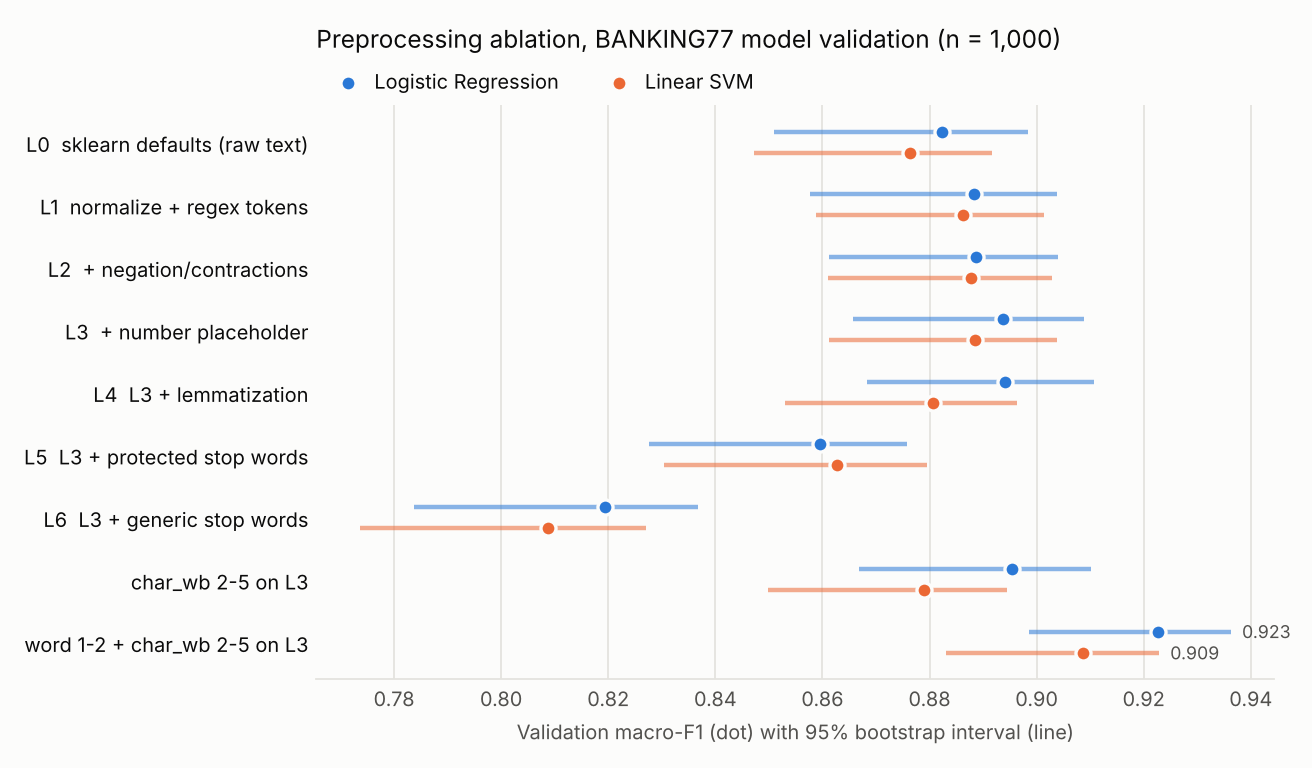

In [7]:
from banking_nlp.figures import ablation_dotplot
from IPython.display import Image
fig = ablation_dotplot(abl, ROOT / 'report' / 'figures' / 'lexical_ablation.png',
                       'Preprocessing ablation, BANKING77 model validation (n = 1,000)')
Image(str(fig))

In [8]:
cands = {f: load_json(P.dev / f'candidate_{f}.json') for f in ('C1', 'C2')}
pd.DataFrame([{ 'family': f, 'config': c['config_id'], 'n_features': c['n_features'],
   **{k: round(v, 4) for k, v in c['val_metrics'].items() if k != 'n'},
   'macro_f1_ci': [round(x, 4) for x in c['val_ci']['macro_f1_ci']],
   'fit_s': round(c['fit_seconds'], 1), 'p50_ms_this_machine': round(c['latency_this_machine']['p50_ms'], 2),
   'artifact_MB': round(c['artifact_bytes'] / 1e6, 1)} for f, c in cands.items()])

,family,config,n_features,accuracy,macro_precision,macro_recall,macro_f1,invalid_predictions,top3_accuracy,macro_f1_ci,fit_s,p50_ms_this_machine,artifact_MB
0,C1,lr|word12+charwb25:L3_numbers|C=100,32369,0.921,0.9268,0.9231,0.9227,0,0.967,"[0.8985, 0.9363]",15.0,1.10,20.6
1,C2,svm|word12+charwb25:L3_numbers|C=1,32369,0.910,0.9155,0.9083,0.9088,0,0.966,"[0.883, 0.9229]",2.7,1.23,20.6


### Development error analysis (model validation, not test)

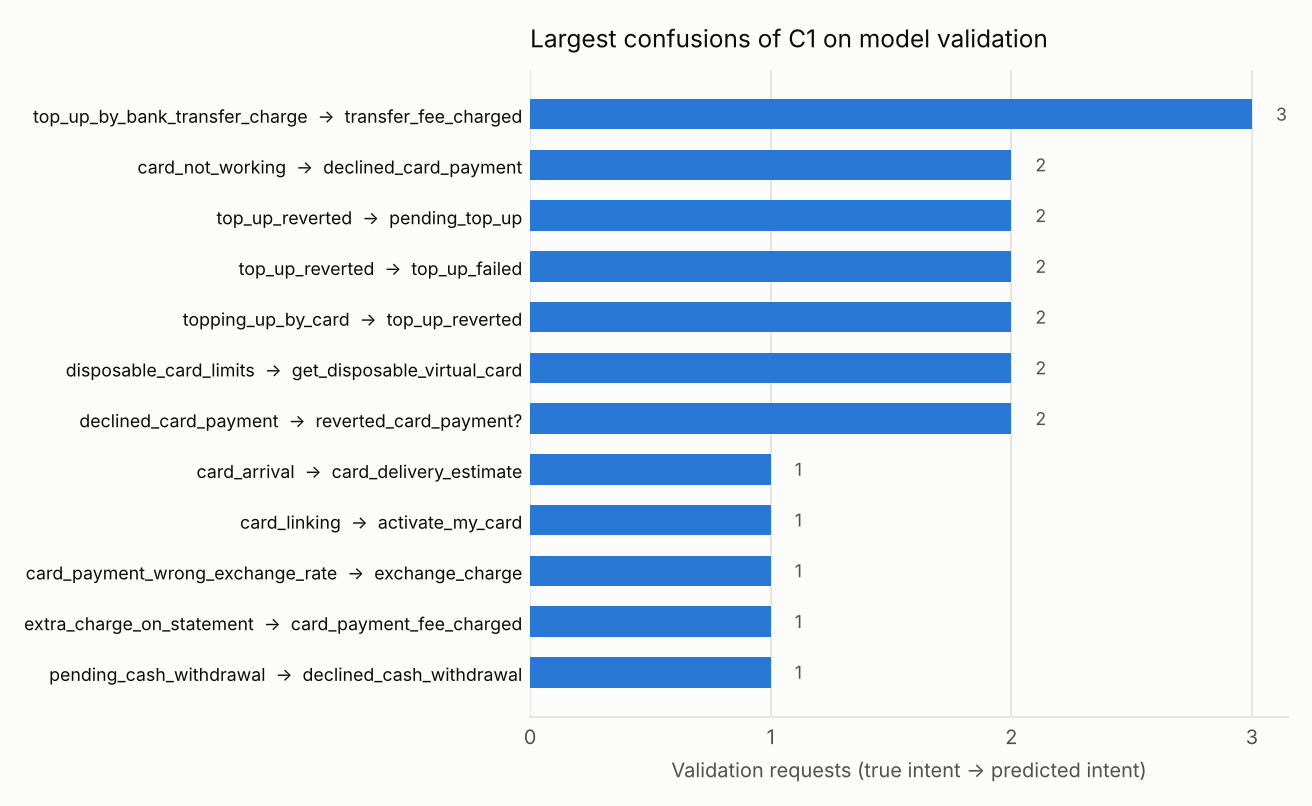

,label_id,label_name,support,precision,recall,f1
35,35,compromised_card,9,0.700,0.778,0.737
25,25,top_up_reverted,15,0.833,0.667,0.741
15,15,top_up_by_bank_transfer_charge,12,0.889,0.667,0.762
33,33,topping_up_by_card,11,0.889,0.727,0.800
67,67,balance_not_updated_after_bank_transfer,18,0.789,0.833,0.811
66,66,top_up_failed,14,0.722,0.929,0.812
61,61,top_up_by_cash_or_cheque,11,0.818,0.818,0.818
65,65,get_disposable_virtual_card,9,0.800,0.889,0.842
51,51,transfer_timing,13,0.846,0.846,0.846
75,75,verify_my_identity,10,0.818,0.900,0.857


In [9]:
from banking_nlp.evaluation import top_confusions, per_class_table
from banking_nlp.figures import confusion_bars
best = max(cands, key=lambda f: cands[f]['val_metrics']['macro_f1'])
pv = pd.read_csv(P.pred_val / f'{best}.csv')
conf = top_confusions(pv.label_id, pv.pred_id, labels, 15)
fig = confusion_bars(conf, ROOT / 'report' / 'figures' / f'{best}_val_confusions.png',
                     f'Largest confusions of {best} on model validation')
display(Image(str(fig)))
per_class_table(pv.label_id, pv.pred_id, labels).head(10).round(3)

In [10]:
val = splits[splits.partition == 'model_val'].set_index('row_id')
err = pv[pv.label_id != pv.pred_id].copy()
err['raw_text'] = err.row_id.map(val.raw_text)
err[['raw_text', 'label_name', 'pred_name', 'margin_top1_top2']].sort_values('margin_top1_top2', ascending=False).head(12)

,raw_text,label_name,pred_name,margin_top1_top2
867,My transfer is pending too long.,balance_not_updated_after_bank_transfer,pending_transfer,0.999503
381,Why should I have to prove my identity?,why_verify_identity,unable_to_verify_identity,0.983162
329,"I tried to add a topup to my account but the money isn't there, anymore. Did I do something wrong?",top_up_reverted,topping_up_by_card,0.961037
59,"Hey, I got charged extra for some reason when I purchased an app. Is this a hidden fee or something? I don't think i...",extra_charge_on_statement,card_payment_fee_charged,0.944561
3,How long does it take for a new card to ship?,card_arrival,card_delivery_estimate,0.887902
272,My cash transaction isn't showing on my account,transfer_not_received_by_recipient,pending_cash_withdrawal,0.875530
128,Today I was out eating and my card was declined. Why's that?,card_not_working,declined_card_payment,0.874029
429,what happened to the money after i put in the wrong info and it got declined,topping_up_by_card,top_up_reverted,0.867296
189,What is the handling fee for transfer?,top_up_by_bank_transfer_charge,transfer_fee_charged,0.858053
256,Why was I charged a fee? I thought shopping was free?,card_payment_fee_charged,cash_withdrawal_charge,0.844273


## 4. Frozen MiniLM embeddings (C3 = LR, C4 = linear SVM)

Requires `sentence-transformers` and access to `sentence-transformers/all-MiniLM-L6-v2` on the Hugging Face hub
(or a local copy). Encoder input is light normalization only. The resolved model revision is written to
`artifacts/embeddings/minilm_dev_meta.json`; copy it into `configs/experiment.json` to pin it.

In [11]:
if RUN_EMBEDDINGS:
    emb_grid = E.run_embeddings(ROOT)
if (P.dev / 'embedding_grid.csv').exists():
    display(pd.read_csv(P.dev / 'embedding_grid.csv')[['config_id', 'macro_f1', 'accuracy', 'top3_accuracy', 'fit_seconds', 'converged']].round(4))
else:
    print('C3/C4 not run yet. On a machine with Hugging Face access:')
    print('  pip install -r requirements.txt  &&  python -m banking_nlp.experiments embeddings')

C3/C4 not run yet. On a machine with Hugging Face access:
  pip install -r requirements.txt  &&  python -m banking_nlp.experiments embeddings


## 5. Freeze the deployment model (all four candidates required)

In [12]:
if RUN_SELECT:
    sel = E.select(ROOT)
    print(sel['deployment_family'], sel['ranking'])
elif (P.frozen / 'selection.json').exists():
    sel = load_json(P.frozen / 'selection.json'); print('frozen:', sel['deployment_family'], sel['ranking'])
else:
    print('Not frozen. Needs candidate_C1..C4.json; then set RUN_SELECT = True.')

Not frozen. Needs candidate_C1..C4.json; then set RUN_SELECT = True.


## 6. Final test pass (runs once, after the freeze)

In [13]:
if RUN_FINAL_TEST:
    E.predict_test(ROOT, i_confirm_configuration_is_frozen=True)
    print(json.dumps(E.score_test(ROOT, i_confirm_configuration_is_frozen=True), indent=1))
else:
    print('Official test set locked.')

Official test set locked.
